<a href="https://colab.research.google.com/github/naik-aarya/Loan-Approval-Prediction-Using-ANN/blob/main/Loan_Approval_Prediction_using_ANN_Aarya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Loan Approval Prediction using ANN**

**Data** : https://drive.google.com/file/d/12P3d1aQAhFhqNJCp5k84d1sS8JRLwn3L/view?usp=sharing


# **Problem Statement**

Financial institutions receive thousands of loan applications every day. Manually evaluating each application is time-consuming and may lead to inconsistencies due to human bias. Banks need an efficient and reliable system that can analyze applicant information and predict whether a loan should be approved.

The objective is to build a machine learning model that learns from historical loan application data and predicts the approval status of new applicants, helping financial institutions make faster and more consistent decisions.

# **Objective**

* Develop a predictive model to determine whether a loan application will be approved or rejected.

* Analyze the factors influencing loan approval decisions.

* Perform data preprocessing, including handling missing values and categorical variables.

* Build ANN algorithm.

* Evaluate model performance using appropriate classification metrics.

# **Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# load data
data = pd.read_csv('loan_approved.csv')

In [ ]:
data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


| Feature                    | Description                                  |
| -------------------------- | -------------------------------------------- |
| **Loan_ID**                | Unique identifier for each loan application  |
| **Gender**                 | Applicant's gender                           |
| **Married**                | Marital status                               |
| **Dependents**             | Number of dependents                         |
| **Education**              | Graduate or Not Graduate                     |
| **Self_Employed**          | Whether the applicant is self-employed       |
| **ApplicantIncome**        | Monthly income of the applicant              |
| **CoapplicantIncome**      | Monthly income of the co-applicant           |
| **LoanAmount**             | Amount of loan requested                     |
| **Loan_Amount_Term**       | Loan repayment term (in months)              |
| **Credit_History**         | Credit history (1 = good, 0 = poor)          |
| **Property_Area**          | Urban, Semiurban, or Rural                   |
| **Loan_Status (Approved)** | Target variable (Y = Approved, N = Rejected) |


# **Basic checks**

In [ ]:
data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
data.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [ ]:
data.shape

(614, 13)

In [ ]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area',
       'Loan_Status (Approved)'],
      dtype='object')

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Loan_ID                 614 non-null    object 
 1   Gender                  601 non-null    object 
 2   Married                 611 non-null    object 
 3   Dependents              599 non-null    object 
 4   Education               614 non-null    object 
 5   Self_Employed           582 non-null    object 
 6   ApplicantIncome         614 non-null    int64  
 7   CoapplicantIncome       614 non-null    float64
 8   LoanAmount              592 non-null    float64
 9   Loan_Amount_Term        600 non-null    float64
 10  Credit_History          564 non-null    float64
 11  Property_Area           614 non-null    object 
 12  Loan_Status (Approved)  614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [ ]:
data.isnull().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [ ]:
data.dtypes

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


In [ ]:
# num_cols
num_data = data.select_dtypes(include = ['int64','float64'])
num_data

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849,0.0,NaN,360.0,1.0
1,4583,1508.0,128.0,360.0,1.0
2,3000,0.0,66.0,360.0,1.0
3,2583,2358.0,120.0,360.0,1.0
4,6000,0.0,141.0,360.0,1.0
...,...,...,...,...,...
609,2900,0.0,71.0,360.0,1.0
610,4106,0.0,40.0,180.0,1.0
611,8072,240.0,253.0,360.0,1.0
612,7583,0.0,187.0,360.0,1.0


In [ ]:
# cat_cols
cat_data = data.select_dtypes(include='object')
cat_data

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status (Approved)
0,LP001002,Male,No,0,Graduate,No,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,Urban,Y
4,LP001008,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...,...
609,LP002978,Female,No,0,Graduate,No,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,Urban,Y


Dependent data type is object even though it has integer values because of 3+.



In [ ]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [ ]:
data.describe(include = 'object')

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status (Approved)
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [ ]:
# drop the Load_Id column
data.drop(columns = 'Loan_ID',inplace = True)

In [ ]:
data

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
0,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y


In [ ]:
cat_data = data.select_dtypes(include='object')
cat_data

,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status (Approved)
0,Male,No,0,Graduate,No,Urban,Y
1,Male,Yes,1,Graduate,No,Rural,N
2,Male,Yes,0,Graduate,Yes,Urban,Y
3,Male,Yes,0,Not Graduate,No,Urban,Y
4,Male,No,0,Graduate,No,Urban,Y
...,...,...,...,...,...,...,...
609,Female,No,0,Graduate,No,Rural,Y
610,Male,Yes,3+,Graduate,No,Rural,Y
611,Male,Yes,1,Graduate,No,Urban,Y
612,Male,Yes,2,Graduate,No,Urban,Y


In [ ]:
# unique values
for x in cat_data:
  print(x,'-->',data[x].unique())

Gender --> ['Male' 'Female' nan]
Married --> ['No' 'Yes' nan]
Dependents --> ['0' '1' '2' '3+' nan]
Education --> ['Graduate' 'Not Graduate']
Self_Employed --> ['No' 'Yes' nan]
Property_Area --> ['Urban' 'Rural' 'Semiurban']
Loan_Status (Approved) --> ['Y' 'N']


In [ ]:
# value counts
for x in cat_data:
  print(data[x].value_counts())

Gender
Male      489
Female    112
Name: count, dtype: int64
Married
Yes    398
No     213
Name: count, dtype: int64
Dependents
0     345
1     102
2     101
3+     51
Name: count, dtype: int64
Education
Graduate        480
Not Graduate    134
Name: count, dtype: int64
Self_Employed
No     500
Yes     82
Name: count, dtype: int64
Property_Area
Semiurban    233
Urban        202
Rural        179
Name: count, dtype: int64
Loan_Status (Approved)
Y    422
N    192
Name: count, dtype: int64


# **Data cleaning**

In [ ]:
# check for duplicates
data.duplicated().sum()

np.int64(0)

In [ ]:
# check for missing values
data.isnull().sum()


,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14
Credit_History,50


**Gender**

In [ ]:
data['Gender'].dtypes

dtype('O')

In [ ]:
data['Gender'].mode()[0]

'Male'

In [ ]:
# fill with mode
data['Gender'] = data['Gender'].fillna(data['Gender'].mode()[0])

**Married**

In [ ]:
data['Married'].dtypes

dtype('O')

In [ ]:
data['Married'].mode()[0]

'Yes'

In [ ]:
# fill with mode
data['Married'] = data['Married'].fillna(data['Married'].mode()[0])

### **Dependents**

In [ ]:
data['Dependents'].dtypes

dtype('O')

In [ ]:
data['Dependents'].mode()[0]

'0'

In [ ]:
data['Dependents'] = data['Dependents'].fillna(data['Dependents'].mode()[0])

**Self_Employed**

In [ ]:
data['Self_Employed'].dtypes

dtype('O')

In [ ]:
data['Self_Employed'].mode()[0]

'No'

In [ ]:
data['Self_Employed'] = data['Self_Employed'].fillna(data['Self_Employed'].mode()[0])

**Credit_History**

In [ ]:
data['Credit_History'].dtypes

dtype('float64')

In [ ]:
data['Credit_History'].unique()

array([ 1.,  0., nan])

In [ ]:
data['Credit_History'].mode()[0]

np.float64(1.0)

In [ ]:
data['Credit_History'] = data['Credit_History'].fillna(data['Credit_History'].mode()[0])

**LoanAmount**

In [ ]:
data['LoanAmount'].dtypes

dtype('float64')

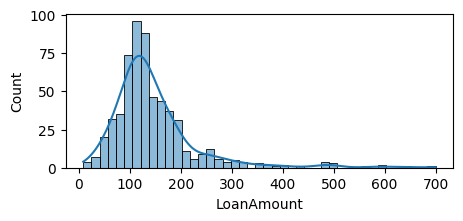

In [ ]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='LoanAmount',kde=True)
plt.show()

LoanAmount distribution is right skewed

In [ ]:
data['LoanAmount'].skew()

np.float64(2.677551679256059)

In [ ]:
# skew>0.5 --> right skew
# skew < -0.5 --> left skew
# skew =[-0.5,0.5]--> normal

In [ ]:
data['LoanAmount'].median()

128.0

In [ ]:
data['LoanAmount']= data['LoanAmount'].fillna(data['LoanAmount'].median())

**Loan_Amount_Term**

In [ ]:
data['Loan_Amount_Term'].dtypes

dtype('float64')

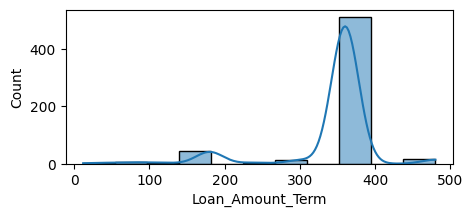

In [ ]:
plt.figure(figsize=(5,2))
sns.histplot(data,x='Loan_Amount_Term',kde=True)
plt.show()

In [ ]:
data['Loan_Amount_Term'].skew()

np.float64(-2.362414124216269)

In [ ]:
data['Loan_Amount_Term'].median()

360.0

In [ ]:
data['Loan_Amount_Term']= data['Loan_Amount_Term'].fillna(data['Loan_Amount_Term'].median())

In [ ]:
data.isnull().sum()

,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


**EDA**

**Outliers**

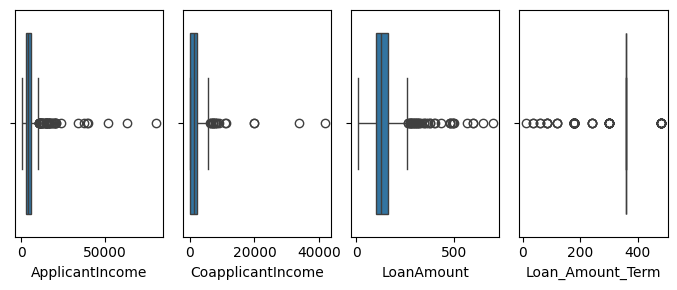

In [ ]:
# ApplicantIncome	CoapplicantIncome	LoanAmount	Loan_Amount_Term
fig,ax = plt.subplots(1,4,figsize = (7,3))
sns.boxplot(data,x='ApplicantIncome',ax = ax[0])
sns.boxplot(data,x='CoapplicantIncome',ax = ax[1])
sns.boxplot(data,x='LoanAmount',ax=ax[2])
sns.boxplot(data,x='Loan_Amount_Term',ax = ax[3])
plt.tight_layout()

There are outliers in all the columns

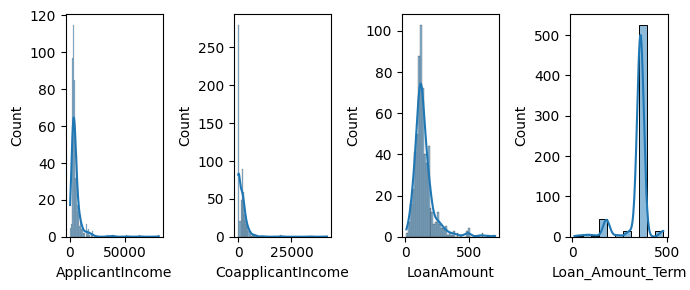

In [ ]:
fig,ax = plt.subplots(1,4,figsize = (7,3))
sns.histplot(data,x='ApplicantIncome',kde=True,ax = ax[0])
sns.histplot(data,x='CoapplicantIncome',kde=True,ax = ax[1])
sns.histplot(data,x='LoanAmount',kde=True,ax=ax[2])
sns.histplot(data,x='Loan_Amount_Term',kde=True,ax = ax[3])
plt.tight_layout()

In [ ]:
A =['ApplicantIncome',	'CoapplicantIncome',	'LoanAmount',	'Loan_Amount_Term']
for x in A:
  print(x,'-->',data[x].skew())

ApplicantIncome --> 6.539513113994625
CoapplicantIncome --> 7.491531216657306
LoanAmount --> 2.743052748820892
Loan_Amount_Term --> -2.4021122563890396


In [ ]:
# since distribution of all columns are skewed will use IQR

**ApplicantIncome**

In [ ]:
# IQR
Q1 = data['ApplicantIncome'].quantile(0.25)
Q3 = data['ApplicantIncome'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

In [ ]:
data[data['ApplicantIncome']<lower_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)


In [ ]:
data[data['ApplicantIncome']>upper_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
9,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N
34,Male,No,3+,Graduate,No,12500,3000.0,320.0,360.0,1.0,Rural,N
54,Female,Yes,1,Graduate,Yes,11500,0.0,286.0,360.0,0.0,Urban,N
67,Male,Yes,1,Graduate,No,10750,0.0,312.0,360.0,1.0,Urban,Y
102,Male,Yes,0,Graduate,No,13650,0.0,128.0,360.0,1.0,Urban,Y
106,Male,Yes,2,Graduate,No,11417,1126.0,225.0,360.0,1.0,Urban,Y
115,Male,Yes,1,Graduate,No,14583,0.0,185.0,180.0,1.0,Rural,Y
119,Female,No,0,Graduate,No,10408,0.0,259.0,360.0,1.0,Urban,Y
126,Male,Yes,3+,Graduate,No,23803,0.0,370.0,360.0,1.0,Rural,Y
128,Male,Yes,1,Graduate,Yes,10513,3850.0,160.0,180.0,0.0,Urban,N


In [ ]:
len(data[(data['ApplicantIncome']<lower_limit)|(data['ApplicantIncome']>upper_limit)])/len(data)*100

8.143322475570033

**CoapplicantIncome**

In [ ]:
# IQR
Q1 = data['CoapplicantIncome'].quantile(0.25)
Q3 = data['CoapplicantIncome'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

In [ ]:
data[data['CoapplicantIncome']<lower_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)


In [ ]:
data[data['CoapplicantIncome']>upper_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
9,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N
12,Male,Yes,2,Graduate,No,3073,8106.0,200.0,360.0,1.0,Urban,Y
38,Male,No,0,Graduate,No,4166,7210.0,184.0,360.0,1.0,Urban,Y
122,Female,No,0,Graduate,No,2137,8980.0,137.0,360.0,0.0,Semiurban,Y
135,Male,Yes,3+,Graduate,No,4000,7750.0,290.0,360.0,1.0,Semiurban,N
177,Male,Yes,3+,Graduate,No,5516,11300.0,495.0,360.0,0.0,Semiurban,N
180,Male,Yes,1,Graduate,No,6400,7250.0,180.0,360.0,0.0,Urban,N
253,Male,Yes,1,Not Graduate,No,2661,7101.0,279.0,180.0,1.0,Semiurban,Y
349,Male,Yes,0,Graduate,No,2625,6250.0,187.0,360.0,1.0,Rural,Y
372,Male,Yes,2,Graduate,Yes,9323,7873.0,380.0,300.0,1.0,Rural,Y


In [ ]:
len(data[(data['CoapplicantIncome']<lower_limit)|(data['CoapplicantIncome']>upper_limit)])/len(data)*100

2.9315960912052117

In [ ]:
# fill with median
data.loc[(data['CoapplicantIncome']<lower_limit)|(data['CoapplicantIncome']>upper_limit),'CoapplicantIncome']=data['CoapplicantIncome'].median()

In [ ]:
len(data[data['CoapplicantIncome']<lower_limit]|data[data['CoapplicantIncome']>upper_limit])/len(data)*100

0.0

**LoanAmount**

In [ ]:
# IQR
Q1 = data['LoanAmount'].quantile(0.25)
Q3 = data['LoanAmount'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

In [ ]:
data[data['LoanAmount']<lower_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)


In [ ]:
data[data['LoanAmount']>upper_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
5,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
9,Male,Yes,1,Graduate,No,12841,1188.5,349.0,360.0,1.0,Semiurban,N
21,Male,Yes,1,Graduate,No,5955,5625.0,315.0,360.0,1.0,Urban,Y
34,Male,No,3+,Graduate,No,12500,3000.0,320.0,360.0,1.0,Rural,N
54,Female,Yes,1,Graduate,Yes,11500,0.0,286.0,360.0,0.0,Urban,N
67,Male,Yes,1,Graduate,No,10750,0.0,312.0,360.0,1.0,Urban,Y
83,Male,Yes,0,Graduate,No,6000,2250.0,265.0,360.0,1.0,Semiurban,N
126,Male,Yes,3+,Graduate,No,23803,0.0,370.0,360.0,1.0,Rural,Y
130,Male,No,0,Graduate,Yes,20166,0.0,650.0,480.0,1.0,Urban,Y
135,Male,Yes,3+,Graduate,No,4000,1188.5,290.0,360.0,1.0,Semiurban,N


In [ ]:
len(data[(data['LoanAmount']<lower_limit)|(data['LoanAmount']>upper_limit)])/len(data)*100


6.677524429967427

**Loan_Amount_Term**

In [ ]:
# IQR
Q1 = data['Loan_Amount_Term'].quantile(0.25)
Q3 = data['Loan_Amount_Term'].quantile(0.75)
IQR = Q3-Q1
lower_limit = Q1-1.5*IQR
upper_limit = Q3+1.5*IQR

In [ ]:
data[data['Loan_Amount_Term']<lower_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
14,Male,Yes,2,Graduate,No,1299,1086.0,17.0,120.0,1.0,Urban,Y
16,Male,No,1,Not Graduate,No,3596,0.0,100.0,240.0,1.0,Urban,Y
62,Male,Yes,0,Not Graduate,Yes,2609,3449.0,165.0,180.0,0.0,Rural,N
66,Male,No,0,Not Graduate,No,3200,2254.0,126.0,180.0,0.0,Urban,N
68,Male,Yes,3+,Not Graduate,Yes,7100,0.0,125.0,60.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...
591,Male,Yes,2,Graduate,Yes,6000,0.0,205.0,240.0,1.0,Semiurban,N
593,Male,Yes,0,Graduate,No,3859,3300.0,142.0,180.0,1.0,Rural,Y
600,Female,No,3+,Graduate,No,416,1188.5,350.0,180.0,1.0,Urban,N
605,Male,Yes,0,Not Graduate,No,2400,3800.0,128.0,180.0,1.0,Urban,N


In [ ]:
data[data['Loan_Amount_Term']>upper_limit]

,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status (Approved)
75,Male,No,0,Graduate,No,3750,0.0,113.0,480.0,1.0,Urban,N
109,Male,Yes,3+,Not Graduate,No,2071,754.0,94.0,480.0,1.0,Semiurban,Y
130,Male,No,0,Graduate,Yes,20166,0.0,650.0,480.0,1.0,Urban,Y
168,Male,No,0,Graduate,No,2237,0.0,63.0,480.0,0.0,Semiurban,N
179,Male,No,0,Not Graduate,No,2333,1451.0,102.0,480.0,0.0,Urban,N
228,Male,Yes,0,Graduate,No,4758,0.0,158.0,480.0,1.0,Semiurban,Y
248,Male,Yes,1,Graduate,No,2882,1843.0,123.0,480.0,1.0,Semiurban,Y
293,Female,No,0,Graduate,No,5417,0.0,143.0,480.0,0.0,Urban,N
298,Female,No,0,Graduate,No,5000,2541.0,151.0,480.0,1.0,Rural,N
358,Male,Yes,0,Not Graduate,No,3000,1666.0,100.0,480.0,0.0,Urban,N


In [ ]:
len(data[(data['Loan_Amount_Term']<lower_limit)|(data['Loan_Amount_Term']>upper_limit)])/len(data)*100

14.332247557003258

In [ ]:
print(data['Loan_Amount_Term'].dtype)

float64


**NOTE** --> len(data[()|()])/len(data)*100

**Encoding**

In [ ]:
# Label Encoder
# Married
# Self_Employed
# Loan_Status (Approved)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
data['married'] = le.fit_transform(data['Married'])
data['self_Employed'] = le.fit_transform(data['Self_Employed'])
data['loan_status'] = le.fit_transform(data['Loan_Status (Approved)'])

In [ ]:
# one hot encoding
# Gender
data = pd.get_dummies(data, columns=['Gender'],dtype ='int')

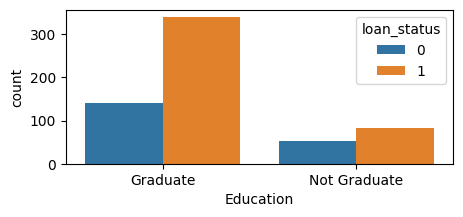

In [ ]:
# target encoding
# Educaton
# Property_Area
plt.figure(figsize=(5,2))
sns.countplot(data,x='Education',hue = 'loan_status')
plt.show()

In [ ]:
data['education'] = data['Education'].map({'Graduate':1,'Not Graduate':0})

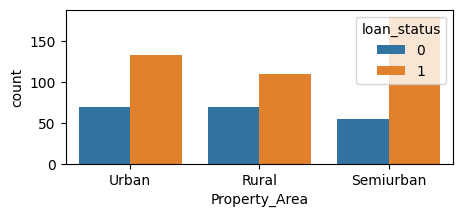

In [ ]:
plt.figure(figsize=(5,2))
sns.countplot(data,x='Property_Area',hue = 'loan_status')
plt.show()

In [ ]:
data['property_area'] = data['Property_Area'].map({'Semiurban':2,'Urban':1,'Rural':0})

In [ ]:
data['Dependents'] = data['Dependents'].replace({'3+':3})

In [ ]:
data['dependents'] = data['Dependents'].astype('int64')

In [ ]:
data.drop(columns=['Married','Dependents',	'Education'	,'Self_Employed',
                  'Property_Area',	'Loan_Status (Approved)' ],inplace=True)

In [ ]:
data

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,married,self_Employed,loan_status,Gender_Female,Gender_Male,education,property_area,dependents
0,5849,0.0,128.0,360.0,1.0,0,0,1,0,1,1,1,0
1,4583,1508.0,128.0,360.0,1.0,1,0,0,0,1,1,0,1
2,3000,0.0,66.0,360.0,1.0,1,1,1,0,1,1,1,0
3,2583,2358.0,120.0,360.0,1.0,1,0,1,0,1,0,1,0
4,6000,0.0,141.0,360.0,1.0,0,0,1,0,1,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
609,2900,0.0,71.0,360.0,1.0,0,0,1,1,0,1,0,0
610,4106,0.0,40.0,180.0,1.0,1,0,1,0,1,1,0,3
611,8072,240.0,253.0,360.0,1.0,1,0,1,0,1,1,1,1
612,7583,0.0,187.0,360.0,1.0,1,0,1,0,1,1,1,2


**Scaling**

In [ ]:
# ApplicantIncome	CoapplicantIncome	LoanAmount	Loan_Amount_Term
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
data[['ApplicantIncome']] = sc.fit_transform(data[['ApplicantIncome']])
data[['CoapplicantIncome']] = sc.fit_transform(data[['CoapplicantIncome']])
data[['LoanAmount']] = sc.fit_transform(data[['LoanAmount']])
data[['Loan_Amount_Term']] = sc.fit_transform(data[['Loan_Amount_Term']])




**Feature Selection**

In [ ]:
df = data[['ApplicantIncome','CoapplicantIncome','LoanAmount','Loan_Amount_Term']]
df.corr()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
ApplicantIncome,1.000000,-0.175488,0.565181,-0.046531
CoapplicantIncome,-0.175488,1.000000,0.104426,-0.005549
LoanAmount,0.565181,0.104426,1.000000,0.036960
Loan_Amount_Term,-0.046531,-0.005549,0.036960,1.000000


<Axes: >

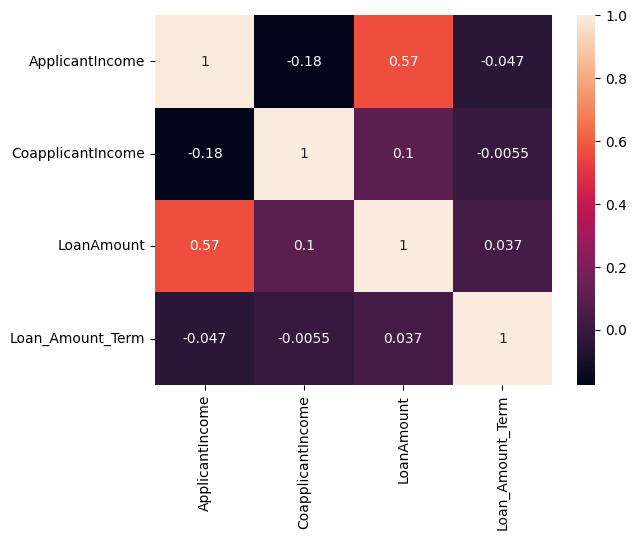

In [ ]:
sns.heatmap(df.corr(),annot = True)

**Split data for x and y**

In [ ]:
x = data.drop(columns = 'loan_status')
y = data.loc[:,'loan_status']

**Split data for training and testing**


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.2)

# **Smote**

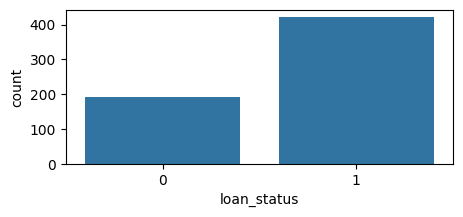

In [ ]:
# check whether data is balanced or not
plt.figure(figsize=(5,2))
sns.countplot(data,x='loan_status')
plt.show()

In [ ]:
# smote
from imblearn.over_sampling import SMOTE
from collections import Counter
smote = SMOTE()
x_sampled , y_sampled = smote.fit_resample(x_train,y_train)

In [ ]:
print('before sampling ',Counter(y_train))
print('after sampling', Counter(y_sampled))

before sampling  Counter({1: 336, 0: 155})
after sampling Counter({0: 336, 1: 336})


# **Model Building**

In [ ]:
from sklearn.neural_network import MLPClassifier
# MLP : multi layer Percenptron
model = MLPClassifier(hidden_layer_sizes=(50,),activation='relu',
                      solver='adam',learning_rate='constant')
model.fit(x_sampled,y_sampled)
y_pred = model.predict(x_test)

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


# **Evaluate the model**

In [ ]:
from sklearn.metrics import confusion_matrix, recall_score, precision_score, accuracy_score ,f1_score

In [ ]:
confusion_matrix(y_test,y_pred)

array([[18, 19],
       [13, 73]])

In [ ]:
accuracy_score(y_test,y_pred)

0.7398373983739838

In [ ]:
recall_score(y_test,y_pred)

0.8488372093023255

In [ ]:
precision_score(y_test,y_pred)

0.7934782608695652

In [ ]:
f1_score(y_test,y_pred)

0.8202247191011236

# **Hyperparameters**

**Number of hidden layers**

Determines how deep the network is.

 * more layers --> can learn complex patterns
 * Too many layers --> may cause overfitting

**Learning rate**

controls step size during weight updates

**Activation Function**

Introduces non-linearity.

**Optimizer**

Algorithm used to update weights.

**ANN using Tensorflow**

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten

**Layers Defined**


In [ ]:
model = Sequential()
# input layer
model.add(Dense(x_sampled.shape[1],activation='relu',input_dim=x_sampled.shape[1]))
model.add(Dense(64,activation='relu')) # hidden layer
model.add(Dense(1,activation='sigmoid')) # output layer

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Compile Model**

Optimizer → Adam

Loss → Binary Crossentropy

Metric → Accuracy



In [ ]:
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])

In [ ]:
model.fit(x_sampled,y_sampled ,batch_size=32 ,epochs=15 ,verbose=1)

Epoch 1/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4881 - loss: 0.7247
Epoch 2/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5432 - loss: 0.6836 
Epoch 3/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5997 - loss: 0.6613 
Epoch 4/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6265 - loss: 0.6436 
Epoch 5/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6920 - loss: 0.6247 
Epoch 6/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7098 - loss: 0.6054 
Epoch 7/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7202 - loss: 0.5883 
Epoch 8/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7336 - loss: 0.5681 
Epoch 9/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7545 - loss: 0.5498 
Epoch 10/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7619 - loss: 0.5354 
Epoch 11/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7753 - loss: 0.5200 
Epoch 12/15
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0

In [ ]:
loss, accuracy = model.evaluate(x_test, y_test)
print("Accuracy:", accuracy)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7236 - loss: 0.6239  
Accuracy: 0.7235772609710693
